In [162]:
import pandas as pd 
import numpy as np 
from matplotlib import pyplot as plt 

In [163]:
df = pd.read_csv('9-homeprices_banglore.csv')
df.sample(5)

,area,bedrooms,price
14,2250,3,101.0
19,800,1,32.0
1,2600,4,120.0
13,1100,2,40.0
11,2785,4,140.0


In [164]:
from sklearn.preprocessing import MinMaxScaler 

scaler_x = MinMaxScaler()
scaler_y = MinMaxScaler()

scaled_x = scaler_x.fit_transform(df[['area' , 'bedrooms']])
scaled_y = scaler_y.fit_transform(df[['price']])

In [165]:
scaled_x

array([[0.08827586, 0.25      ],
       [0.62068966, 0.75      ],
       [0.22068966, 0.5       ],
       [0.24862069, 0.5       ],
       [0.13793103, 0.25      ],
       [0.12758621, 0.25      ],
       [0.6662069 , 0.75      ],
       [0.86206897, 0.75      ],
       [0.17586207, 0.5       ],
       [1.        , 1.        ],
       [0.34482759, 0.5       ],
       [0.68448276, 0.75      ],
       [0.06896552, 0.25      ],
       [0.10344828, 0.25      ],
       [0.5       , 0.5       ],
       [0.12931034, 0.25      ],
       [0.13103448, 0.5       ],
       [0.25517241, 0.5       ],
       [0.67931034, 0.5       ],
       [0.        , 0.        ]])

In [166]:
scaled_y

array([[0.05237037],
       [0.65185185],
       [0.22222222],
       [0.31851852],
       [0.14074074],
       [0.04444444],
       [0.76296296],
       [0.91111111],
       [0.13333333],
       [1.        ],
       [0.37037037],
       [0.8       ],
       [0.04444444],
       [0.05925926],
       [0.51111111],
       [0.07407407],
       [0.11851852],
       [0.20740741],
       [0.51851852],
       [0.        ]])

In [167]:
scaled_y.shape

(20, 1)

In [168]:
scaled_y.reshape(len(scaled_y))

array([0.05237037, 0.65185185, 0.22222222, 0.31851852, 0.14074074,
       0.04444444, 0.76296296, 0.91111111, 0.13333333, 1.        ,
       0.37037037, 0.8       , 0.04444444, 0.05925926, 0.51111111,
       0.07407407, 0.11851852, 0.20740741, 0.51851852, 0.        ])

In [169]:
import random
random.randint(0,6)

3

In [170]:
def stochastic_gradient_descent(X, y_true, epochs , learning_rate=0.01):
    numbers_features = X.shape[1]
    w = np.ones(shape=(numbers_features))
    b = 0 
    total_samples = X.shape[0]
    
    cost_list = []
    epochs_list = []
    
    for i in range(epochs):
        random_index = random.randint(0,total_samples-1)
        
        sample_x = X[random_index]
        sample_y = y_true[random_index]
        
        y_predicted = np.dot(w,sample_x.T) + b
        
        w_grad = -(2/total_samples) * (sample_x.T.dot(sample_y - y_predicted))
        b_grad = -(2/total_samples) * (sample_y - y_predicted)
        
        w = w - learning_rate * w_grad
        b = b - learning_rate * b_grad
        
        cost = np.square(sample_y - y_predicted) 
        
        if i % 100 == 0:
            cost_list.append(cost)
            epochs_list.append(i)
            
    return w, b , cost , cost_list , epochs_list 


w, b , cost , cost_list , epochs_list  = stochastic_gradient_descent(scaled_x , scaled_y.reshape(len(scaled_y)) , 10000)

w , b , cost

(array([0.70873207, 0.67702886]),
 np.float64(-0.22966872989590847),
 np.float64(0.01005606025373897))

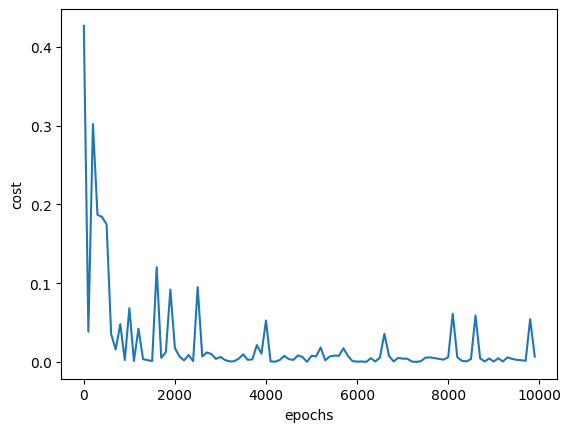

In [171]:
plt.xlabel('epochs')
plt.ylabel('cost')
plt.plot(epochs_list,cost_list)

In [172]:
def predict(area, bedrooms, w, b):
    data = pd.DataFrame([[area,bedrooms]] , columns=['area' , 'bedrooms'])
    
    scaled_X = scaler_x.transform(data)[0]
    
    scaled_price = w[0] * scaled_X[0] + w[1] * scaled_X[1] + b
    
    return scaler_y.inverse_transform([[scaled_price]])[0][0]



In [173]:
predict(2600 , 4 , w , b)

np.float64(128.93075409306763)

In [174]:
predict(1000, 2 , w , b)

np.float64(30.442985660884812)